# AA3 · Parcial II · Cuaderno 1: Recurrentes
**Alumno:** Edgar Ivan Galvez Ortega
**Datos:** ticker **SMH** (VanEck Semiconductor ETF), precios diarios de Yahoo Finanzas (`period="5y"`, `interval="1d"`)

Pronóstico del cierre de SMH con una **red recurrente (LSTM)**, comparada contra la línea base de sentido común «mañana = hoy». Sale de la Práctica 3, parte A («Tu cuaderno de pronóstico»).

> **Recordatorio ético:** es un ejercicio académico, no una recomendación de inversión.

## 1. Datos
Reglas de los Bloques 2 y 3 de la práctica:
1. Descarga de Yahoo Finanzas con precios ajustados (`auto_adjust=True`) y sin la última vela, que puede estar en formación.
2. **División cronológica** 70 % / 15 % / 15 %, sin mezclar días.
3. **Normalización solo con los estadísticos del entrenamiento.**
4. **Ventanas** de 30 días con `timeseries_dataset_from_array` para predecir el cierre del día siguiente (`horizonte = 1`).

### 1.1 Entorno
Instala lo que falte, fija Keras 3 con PyTorch como *backend* (antes de importar Keras) y revisa la GPU. `yfinance` se importa **antes** que `torch` y `keras` (en Colab, al revés falla la descarga).

In [1]:
import os
import sys
import importlib.util
import subprocess

EN_COLAB = importlib.util.find_spec("google.colab") is not None

# Instala solo lo que falte (en un entorno ya preparado no hace nada)
paquetes = {"yfinance": "yfinance", "sklearn": "scikit-learn", "keras": "keras", "torch": "torch",
            "tensorflow": "tensorflow",   # tf.data: lo usa timeseries_dataset_from_array
            "pandas": "pandas", "matplotlib": "matplotlib"}
faltantes = [pip for mod, pip in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print(f"Instalando paquetes faltantes: {faltantes}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
else:
    print("Todas las dependencias ya están instaladas.")

import yfinance as yf                      # ANTES que torch y keras

os.environ["KERAS_BACKEND"] = "torch"      # ANTES de importar keras
import torch
import keras

print("--- Auditoría de Entorno ---")
print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local / servidor'} · Python {sys.version.split()[0]}")
print(f"Keras {keras.__version__} · backend: {keras.backend.backend()} · PyTorch {torch.__version__} · yfinance {yf.__version__}")
assert int(keras.__version__.split(".")[0]) >= 3, "Se necesita Keras 3"
assert keras.backend.backend() == "torch", "Keras ya estaba importado con otro backend: reinicia el kernel"
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)")
else:
    print("AVISO: sin GPU. El modelo es pequeño y también corre en CPU.")

Todas las dependencias ya están instaladas.
--- Auditoría de Entorno ---
Entorno: Local / servidor · Python 3.13.0
Keras 3.15.1 · backend: torch · PyTorch 2.6.0+cu124 · yfinance 1.7.0
GPU: NVIDIA GeForce RTX 4070 SUPER (12.0 GB)


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print(f"NumPy {np.__version__} · pandas {pd.__version__} · semilla {SEED}")

NumPy 2.3.5 · pandas 3.0.5 · semilla 42


### 1.2 Formulario de la serie
En Colab esta celda se ve como formulario. Solo se eligen `ticker` (distinto de ALC) y `usar_volumen`; `period`, `interval`, `horizonte` y `ventana` se quedan **igual que en la práctica**.

In [3]:
#@title Seleccione la serie { run: "auto" }
ticker = "SMH" #@param ["SMH", "NVDA", "AAPL", "MSFT", "WALMEX.MX", "AMXB.MX", "^MXX", "BTC-USD"] {allow-input: true}
usar_volumen = False #@param {type:"boolean"}

assert ticker.strip().upper() != "ALC", "El ticker debe ser distinto de ALC"

# Parámetros fijos de la práctica (Bloques 2 y 3)
period = "5y"
interval = "1d"
horizonte = 1       # predecir el cierre del día hábil siguiente
ventana = 30        # 30 días de historia por ejemplo
batch_size = 32

variables = ["Close", "Volume"] if usar_volumen else ["Close"]
print(f"Serie: {ticker} · periodo: {period} · intervalo: {interval} · horizonte: {horizonte} · ventana: {ventana}")
print(f"Variables de entrada: {variables} · objetivo: Close")

Serie: SMH · periodo: 5y · intervalo: 1d · horizonte: 1 · ventana: 30
Variables de entrada: ['Close'] · objetivo: Close


### 1.3 Descarga
`auto_adjust=True` corrige dividendos y *splits*; se descarta la última vela porque puede no ser definitiva. Cada descarga se respalda en `datos/` por si falla la conexión.

In [4]:
os.makedirs("datos", exist_ok=True)
try:
    yf.set_tz_cache_location(os.path.abspath("datos/.yf_cache"))
except Exception:
    pass
respaldo = f"datos/respaldo_{ticker.replace('^', '')}_{period}_{interval}.csv"

try:
    df = yf.download(ticker, period=period, interval=interval,
                     multi_level_index=False, auto_adjust=True, progress=False)
    df = df.dropna().copy()
    df = df.iloc[:-1]                       # la última vela puede estar "en formación"
    if df.empty:
        raise ValueError("la descarga llegó vacía")
    df.to_csv(respaldo)
    origen = "Yahoo Finanzas"
except Exception as error:
    print(f"AVISO: no se pudo descargar ({error}). Se usa el respaldo local.")
    df = pd.read_csv(respaldo, index_col=0, parse_dates=True)
    origen = respaldo

print(f"{ticker}: {len(df)} velas de {interval} ({df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d}) [origen: {origen}]")
df.tail()

SMH: 1253 velas de 1d (2021-11-08 → 2026-11-04) [origen: Yahoo Finanzas]


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-29,561.669983,565.869995,555.500000,558.929993,6017500
2026-10-30,522.489990,535.320007,511.630005,532.580017,17602000
2026-11-02,508.309998,532.760010,506.440002,529.049988,8865800
2026-11-03,518.520020,524.700012,515.489990,520.679993,9095800
2026-11-04,504.269989,522.200012,497.329987,511.170013,13413900


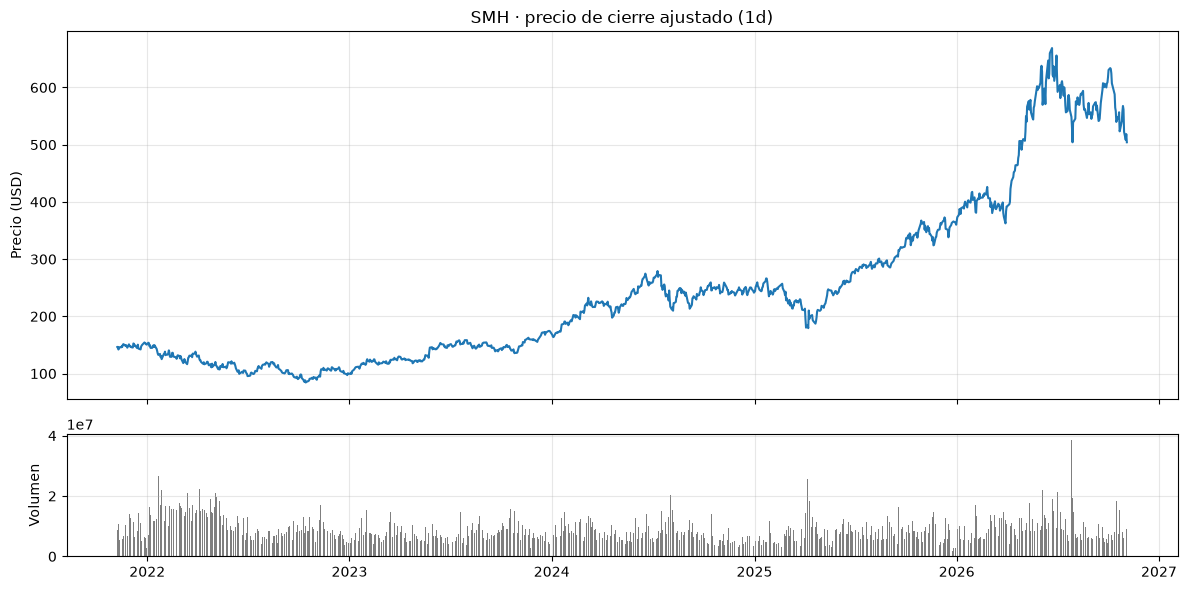

Serie de trabajo: 1253 muestras · variables: ['Close'] · faltantes: 0


,Close
count,1253.00
mean,243.92
std,143.45
min,84.45
25%,131.51
50%,216.64
75%,289.61
max,668.91


In [5]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ejes[0].plot(df.index, df["Close"], color="tab:blue")
ejes[0].set_title(f"{ticker} · precio de cierre ajustado ({interval})")
ejes[0].set_ylabel("Precio (USD)")
ejes[1].bar(df.index, df["Volume"], color="tab:gray")
ejes[1].set_ylabel("Volumen")
plt.tight_layout()
plt.show()

df = df[variables].copy()
print(f"Serie de trabajo: {len(df)} muestras · variables: {list(df.columns)} · faltantes: {int(df.isna().sum().sum())}")
df.describe().round(2)

### 1.4 División cronológica: 70 % / 15 % / 15 %
El entrenamiento es el periodo más antiguo, la validación el intermedio y la prueba el más reciente (se usa una sola vez). Si se usa el volumen, entra como $\log(1 + \text{volumen})$ para comprimir sus picos.

--- División cronológica ---
Entrenamiento:   877 días (2021-11-08 → 2025-05-07)
Validación:      187 días (2025-05-08 → 2026-02-04)
Prueba:          189 días (2026-02-05 → 2026-11-04)


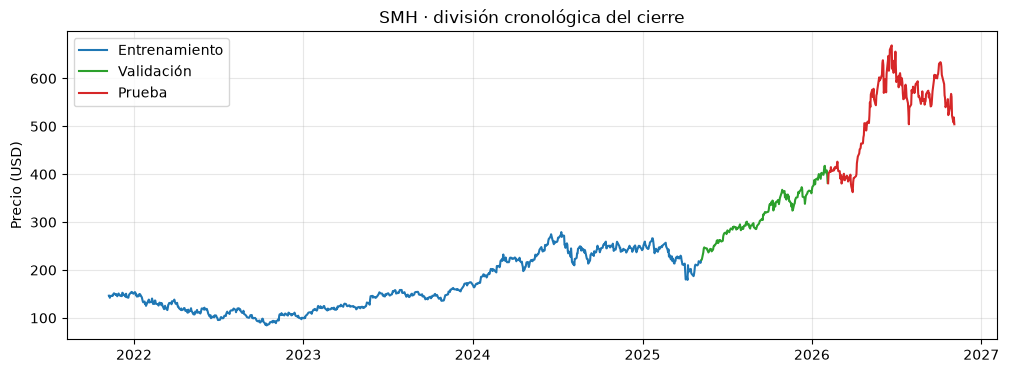

In [6]:
datos = df.copy()
if "Volume" in variables:
    datos["Volume"] = np.log1p(datos["Volume"])

raw_data = datos[variables].values.astype("float32")   # columna 0 = Close (objetivo)
fechas = datos.index
n_variables = raw_data.shape[1]

num_train = int(0.70 * len(raw_data))
num_val = int(0.15 * len(raw_data))
num_test = len(raw_data) - num_train - num_val

print("--- División cronológica ---")
print(f"Entrenamiento: {num_train:>5} días ({fechas[0]:%Y-%m-%d} → {fechas[num_train - 1]:%Y-%m-%d})")
print(f"Validación:    {num_val:>5} días ({fechas[num_train]:%Y-%m-%d} → {fechas[num_train + num_val - 1]:%Y-%m-%d})")
print(f"Prueba:        {num_test:>5} días ({fechas[num_train + num_val]:%Y-%m-%d} → {fechas[-1]:%Y-%m-%d})")

plt.figure(figsize=(12, 4))
plt.plot(fechas[:num_train], raw_data[:num_train, 0], color="tab:blue", label="Entrenamiento")
plt.plot(fechas[num_train:num_train + num_val], raw_data[num_train:num_train + num_val, 0], color="tab:green", label="Validación")
plt.plot(fechas[num_train + num_val:], raw_data[num_train + num_val:, 0], color="tab:red", label="Prueba")
plt.title(f"{ticker} · división cronológica del cierre")
plt.ylabel("Precio (USD)")
plt.legend()
plt.show()

### 1.5 Normalización con los estadísticos del entrenamiento
Media y desviación **solo del 70 % más antiguo**, aplicadas igual a validación y prueba. `media_close` y `std_close` regresan los errores a dólares. También medimos qué parte de validación y prueba queda **fuera del rango** que la red vio al entrenar: SMH subió mucho en estos años, así que la red tendrá que extrapolar.

In [7]:
media = raw_data[:num_train].mean(axis=0)
std = raw_data[:num_train].std(axis=0)
data_norm = (raw_data - media) / std
media_close, std_close = float(media[0]), float(std[0])

print(f"Media del cierre (entrenamiento):      {media_close:.2f}")
print(f"Desviación del cierre (entrenamiento): {std_close:.2f}")

min_train, max_train = data_norm[:num_train, 0].min(), data_norm[:num_train, 0].max()
fuera_de_rango = {}
for nombre, tramo in [("Validación", data_norm[num_train:num_train + num_val, 0]),
                      ("Prueba", data_norm[num_train + num_val:, 0])]:
    fuera_de_rango[nombre] = np.mean((tramo < min_train) | (tramo > max_train)) * 100
    print(f"{nombre}: {fuera_de_rango[nombre]:.1f} % de los precios fuera del rango de entrenamiento "
          f"(máximo de entrenamiento: {max_train * std_close + media_close:.2f} USD)")

Media del cierre (entrenamiento):      166.93
Desviación del cierre (entrenamiento): 54.35
Validación: 79.7 % de los precios fuera del rango de entrenamiento (máximo de entrenamiento: 279.16 USD)
Prueba: 100.0 % de los precios fuera del rango de entrenamiento (máximo de entrenamiento: 279.16 USD)


### 1.6 Ventanas deslizantes
Cada ejemplo son 30 días y su objetivo es el cierre `horizonte` días después del último día de la ventana (`delay = ventana + horizonte − 1`). Los límites (`end_index = num_* − horizonte`) evitan que una ventana o su objetivo crucen al conjunto siguiente. En entrenamiento se mezclan **ventanas completas**, no días.

In [8]:
delay = ventana + horizonte - 1
objetivo = data_norm[:, 0]

def crear_dataset(inicio, fin, mezclar=False):
    # Ventanas del tramo [inicio, fin): cada conjunto usa solo su propio periodo
    return keras.utils.timeseries_dataset_from_array(
        data_norm[:-horizonte], targets=objetivo[delay:], sequence_length=ventana,
        batch_size=batch_size, shuffle=mezclar, seed=SEED, start_index=inicio, end_index=fin)

train_ds = crear_dataset(0, num_train - horizonte, mezclar=True)
val_ds = crear_dataset(num_train, num_train + num_val - horizonte)
test_ds = crear_dataset(num_train + num_val, None)

for nombre, ds in [("Entrenamiento", train_ds), ("Validación", val_ds), ("Prueba", test_ds)]:
    print(f"{nombre:<14} {sum(x.shape[0] for x, _ in ds):>5} ventanas")

# Verificación manual con la primera ventana de prueba
x, y = next(iter(test_ds))
i0 = num_train + num_val
print(f"\nPrimera ventana de prueba: {fechas[i0]:%Y-%m-%d} → {fechas[i0 + ventana - 1]:%Y-%m-%d}")
print(f"Objetivo: cierre del {fechas[i0 + delay]:%Y-%m-%d} = {float(y[0]) * std_close + media_close:.2f} "
      f"(en la tabla: {raw_data[i0 + delay, 0]:.2f})")
print(f"Forma de un lote: {tuple(x.shape)} → (lote, pasos, variables)")

Entrenamiento    847 ventanas
Validación       157 ventanas
Prueba           159 ventanas

Primera ventana de prueba: 2026-02-05 → 2026-03-19
Objetivo: cierre del 2026-03-20 = 384.74 (en la tabla: 384.74)
Forma de un lote: (32, 30, 1) → (lote, pasos, variables)


## 2. Línea base
**«Mañana = hoy»** (Bloque 4): para cada ventana, la predicción es su último cierre. No se entrena nada; solo se mide el error en dólares. Es la vara contra la que se compara la red.

In [9]:
def evaluar_linea_base(dataset, metrica="mae"):
    # Error en dólares (MAE o RMSE) de predecir que el cierre de mañana es el último cierre de la ventana
    error_total, n = 0.0, 0
    for muestras, objetivos in dataset:
        error = muestras[:, -1, 0].numpy() - objetivos.numpy()
        error_total += (np.abs(error) if metrica == "mae" else error ** 2).sum()
        n += len(error)
    promedio = error_total / n
    return (promedio if metrica == "mae" else np.sqrt(promedio)) * std_close

mae_base_val = evaluar_linea_base(val_ds)
mae_base_test = evaluar_linea_base(test_ds)
rmse_base_test = evaluar_linea_base(test_ds, metrica="rmse")

filas_resultados = {"Línea base (mañana = hoy)": {"MAE val": mae_base_val, "MAE prueba": mae_base_test,
                                                  "RMSE prueba": rmse_base_test, "Parámetros": 0}}

print(f"--- Línea base · {ticker} ({interval}), horizonte {horizonte} ---")
print(f"MAE validación: {mae_base_val:.3f} USD")
print(f"MAE prueba:     {mae_base_test:.3f} USD ({100 * mae_base_test / raw_data[num_train + num_val:, 0].mean():.2f} % del precio medio de prueba)")
print(f"RMSE prueba:    {rmse_base_test:.3f} USD")

--- Línea base · SMH (1d), horizonte 1 ---
MAE validación: 4.515 USD
MAE prueba:     12.393 USD (2.35 % del precio medio de prueba)
RMSE prueba:    16.094 USD


## 3. Modelo
**Elegí una LSTM de 32 unidades** (Bloque 6.1). Por qué, con lo que vimos en la práctica:

- **Es la recurrente "por defecto" y fue de las mejores del Bloque 6.** Su estado de celda se actualiza *sumando*, así que el gradiente sobrevive a lo largo de los 30 días de la ventana.
- **Es la más rápida de entrenar:** usa la implementación de cuDNN. La LSTM con *dropout* recurrente pierde cuDNN y es unas 10 veces más lenta por época: con ventanas de solo 30 días no vale ese costo.
- **Más capacidad no garantiza un mejor modelo** (lección del Bloque 6): la GRU apilada tiene el doble de capas recurrentes. Con ~850 ventanas de entrenamiento, una red pequeña sobreajusta menos.
- **La bidireccional no tiene sentido para pronosticar:** la dirección que lee hacia atrás termina en el día más antiguo, el menos útil para predecir mañana. Sirve para clasificar secuencias completas, no para pronóstico.
- Es la misma red que usa el Bloque 8 de la práctica para los diagnósticos (retraso de un día y dirección), así que los resultados se pueden comparar.

**Entrenamiento:** pérdida MSE, métrica MAE, RMSprop (como Chollet, cap. 13), hasta 50 épocas con `EarlyStopping` (paciencia 8, restaura los mejores pesos según `val_loss`).

In [10]:
def graficar_curvas(history, titulo="", metrica="mae"):
    entr, val = history.history[metrica], history.history[f"val_{metrica}"]
    epocas = range(1, len(entr) + 1)
    mejor = int(np.argmin(history.history["val_loss"]))
    plt.figure(figsize=(8, 4))
    plt.plot(epocas, entr, "o--", color="tab:blue", label=f"Entrenamiento ({metrica})")
    plt.plot(epocas, val, "o-", color="tab:orange", label=f"Validación ({metrica})")
    plt.axvline(mejor + 1, color="gray", linestyle=":", label=f"Mejor época: {mejor + 1}")
    plt.title(f"Curvas de aprendizaje · {titulo} (MAE normalizado)")
    plt.xlabel("Época")
    plt.ylabel(metrica.upper())
    plt.legend()
    plt.show()

keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(ventana, n_variables), name="Ventana")
x = layers.LSTM(32, name="LSTM_32")(inputs)
outputs = layers.Dense(1, name="Cierre_futuro")(x)
modelo_lstm = keras.Model(inputs, outputs, name="LSTM")
modelo_lstm.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Ventana (InputLayer)            │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM_32 (LSTM)                  │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Cierre_futuro (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1412.)
  outputs, h_n, c_n = torch._VF.lstm(


Epoch 24: early stopping
Restoring model weights from the end of the best epoch: 16.


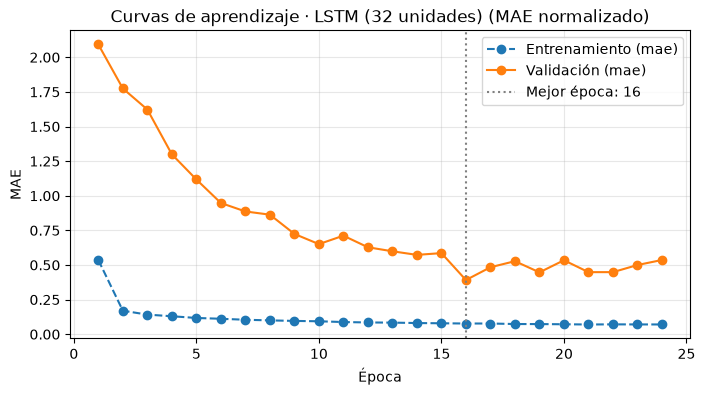

--- LSTM (32 unidades) ---
Épocas: 24 (mejor: 16) · 0.16 s/época
MAE validación: 21.274 USD  (línea base: 4.515)
MAE prueba:     200.996 USD  (línea base: 12.393)
RMSE prueba:    210.737 USD  (línea base: 16.094)
→ En prueba, la LSTM NO supera a la línea base (+1521.8 % de MAE).


In [11]:
NOMBRE_MODELO = "LSTM (32 unidades)"
modelo_lstm.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])

inicio = time.perf_counter()
historia = modelo_lstm.fit(
    train_ds, epochs=50, validation_data=val_ds, shuffle=False, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1)])
epocas_entrenadas = len(historia.history["loss"])
seg_por_epoca = (time.perf_counter() - inicio) / epocas_entrenadas
graficar_curvas(historia, titulo=NOMBRE_MODELO)

mae_val = modelo_lstm.evaluate(val_ds, verbose=0)[1] * std_close
mse_test, mae_test = modelo_lstm.evaluate(test_ds, verbose=0)
mae_test, rmse_test = mae_test * std_close, np.sqrt(mse_test) * std_close
filas_resultados[NOMBRE_MODELO] = {"MAE val": mae_val, "MAE prueba": mae_test, "RMSE prueba": rmse_test,
                                   "Parámetros": modelo_lstm.count_params()}

print(f"--- {NOMBRE_MODELO} ---")
print(f"Épocas: {epocas_entrenadas} (mejor: {int(np.argmin(historia.history['val_loss'])) + 1}) · {seg_por_epoca:.2f} s/época")
print(f"MAE validación: {mae_val:.3f} USD  (línea base: {mae_base_val:.3f})")
print(f"MAE prueba:     {mae_test:.3f} USD  (línea base: {mae_base_test:.3f})")
print(f"RMSE prueba:    {rmse_test:.3f} USD  (línea base: {rmse_base_test:.3f})")
print(f"→ En prueba, la LSTM {'SÍ' if mae_test < mae_base_test else 'NO'} supera a la línea base "
      f"({(mae_test / mae_base_test - 1) * 100:+.1f} % de MAE).")

## 4. Resultados
### 4.1 Pronóstico de los próximos 30 días hábiles
Funciones del Bloque 4 (`pronosticar_futuro()` y `dibujar_pronostico()`). El pronóstico es **recursivo**: cada cierre predicho entra a la ventana como si fuera real. Si se usa el volumen, el volumen futuro es el promedio de la última ventana. Las fechas avanzan por días hábiles (no descuenta festivos).

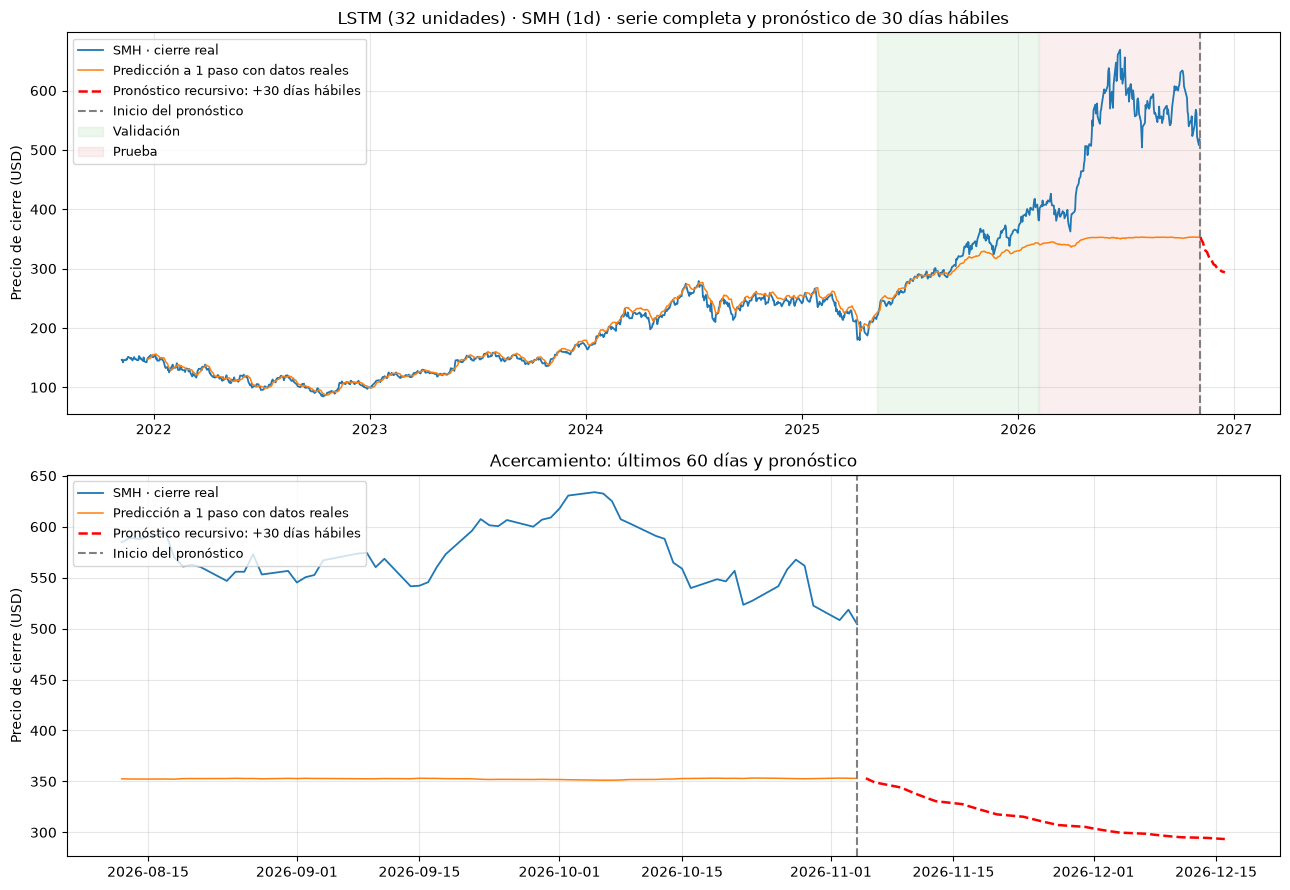

--- Pronóstico · LSTM (32 unidades) · SMH ---
Último cierre conocido (2026-11-04): 504.27
Día 1  (2026-11-05): 353.07 (-30.0 %)
Día 30 (2026-12-16): 293.44 (-41.8 %)
Promedio del cierre en el entrenamiento: 166.93


,Cierre pronosticado (USD),Cambio vs. último cierre (%)
Fecha (día hábil),,
2026-11-05,353.070007,-29.980000
2026-11-11,336.839996,-33.200001
2026-11-18,322.480011,-36.049999
2026-11-25,311.010010,-38.330002
2026-12-02,302.329987,-40.049999
2026-12-09,296.739990,-41.160000
2026-12-16,293.440002,-41.810001


In [12]:
pasos_futuro = 30

def fechas_futuras(pasos):
    if interval == "1d":
        return pd.bdate_range(fechas[-1] + pd.offsets.BDay(1), periods=pasos)
    paso = fechas.to_series().diff().median()
    return pd.date_range(fechas[-1] + paso, periods=pasos, freq=paso)


def pronostico_recursivo(modelo, base_norm, pasos):
    # Pronóstico recursivo de `pasos` cierres después del último dato de `base_norm` (normalizado). Regresa USD.
    n = len(base_norm)
    serie = np.concatenate([base_norm, np.zeros((pasos, n_variables), dtype="float32")])
    if n_variables > 1:
        serie[n:, 1] = base_norm[-ventana:, 1].mean()     # volumen futuro = promedio de la última ventana
    for t in range(n, n + pasos):
        fin = t - horizonte + 1
        x = serie[fin - ventana:fin][np.newaxis]
        serie[t, 0] = keras.ops.convert_to_numpy(modelo.predict_on_batch(x))[0, 0]
    return serie[n:, 0] * std_close + media_close


def pronosticar_futuro(modelo, pasos=None):
    return pronostico_recursivo(modelo, data_norm, pasos or pasos_futuro)


def dibujar_pronostico(nombre, pred_real, futuro, pasos_zoom=60):
    pasos = len(futuro)
    cierre = raw_data[:, 0]
    fechas_pred = fechas[delay:]
    fechas_fut = fechas_futuras(pasos)
    fig, ejes = plt.subplots(2, 1, figsize=(13, 9))
    for eje, desde in [(ejes[0], 0), (ejes[1], len(cierre) - pasos_zoom)]:
        d = max(desde - delay, 0)
        eje.plot(fechas[desde:], cierre[desde:], color="tab:blue", linewidth=1.3, label=f"{ticker} · cierre real")
        eje.plot(fechas_pred[d:], pred_real[d:], color="tab:orange", linewidth=1.1, label=f"Predicción a {horizonte} paso con datos reales")
        eje.plot(fechas_fut, futuro, "--", color="red", linewidth=1.8, label=f"Pronóstico recursivo: +{pasos} días hábiles")
        eje.axvline(fechas[-1], color="gray", linestyle="--", label="Inicio del pronóstico")
        eje.set_ylabel("Precio de cierre (USD)")
    ejes[0].axvspan(fechas[num_train], fechas[num_train + num_val - 1], color="tab:green", alpha=0.08, label="Validación")
    ejes[0].axvspan(fechas[num_train + num_val], fechas[-1], color="tab:red", alpha=0.08, label="Prueba")
    ejes[0].set_title(f"{nombre} · {ticker} ({interval}) · serie completa y pronóstico de {pasos} días hábiles")
    ejes[1].set_title(f"Acercamiento: últimos {pasos_zoom} días y pronóstico")
    for eje in ejes:
        eje.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()

    cambio = (futuro / cierre[-1] - 1) * 100
    print(f"--- Pronóstico · {nombre} · {ticker} ---")
    print(f"Último cierre conocido ({fechas[-1]:%Y-%m-%d}): {cierre[-1]:.2f}")
    print(f"Día 1  ({fechas_fut[0]:%Y-%m-%d}): {futuro[0]:.2f} ({cambio[0]:+.1f} %)")
    print(f"Día {pasos} ({fechas_fut[-1]:%Y-%m-%d}): {futuro[-1]:.2f} ({cambio[-1]:+.1f} %)")
    print(f"Promedio del cierre en el entrenamiento: {media_close:.2f}")


pred_real = keras.ops.convert_to_numpy(modelo_lstm.predict(crear_dataset(0, None), verbose=0))[:, 0] * std_close + media_close
futuro = pronosticar_futuro(modelo_lstm)
dibujar_pronostico(NOMBRE_MODELO, pred_real, futuro)

tabla_pronostico = pd.DataFrame({"Cierre pronosticado (USD)": futuro,
                                 "Cambio vs. último cierre (%)": (futuro / raw_data[-1, 0] - 1) * 100},
                                index=fechas_futuras(pasos_futuro).date)
tabla_pronostico.index.name = "Fecha (día hábil)"
tabla_pronostico.iloc[[0, 4, 9, 14, 19, 24, 29]].round(2)

### 4.2 Tabla de resultados
MAE y RMSE de **prueba** en dólares (también el MAE de validación y el número de parámetros), una fila por modelo.

In [13]:
resultados = pd.DataFrame(filas_resultados).T
resultados["MAE prueba vs. base (%)"] = (resultados["MAE prueba"] / mae_base_test - 1) * 100
resultados["Parámetros"] = resultados["Parámetros"].astype(int)
resultados = resultados.round(3)
resultados

,MAE val,MAE prueba,RMSE prueba,Parámetros,MAE prueba vs. base (%)
Línea base (mañana = hoy),4.515,12.393,16.094,0,0.00
LSTM (32 unidades),21.274,200.996,210.737,4385,1521.85


## 5. Conclusión
Antes de responder si SMH subirá o bajará, revisamos qué tanto hay que creerle al pronóstico, con las tres pruebas de la práctica.

### 5.1 El «retraso de un día» (Bloque 8.1)
Si la red solo aprendió a copiar el último cierre, su curva es la real **desplazada un día** y su predicción queda más cerca de lo que ya sabía que de lo que debía predecir.

c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1412.)
  outputs, h_n, c_n = torch._VF.lstm(


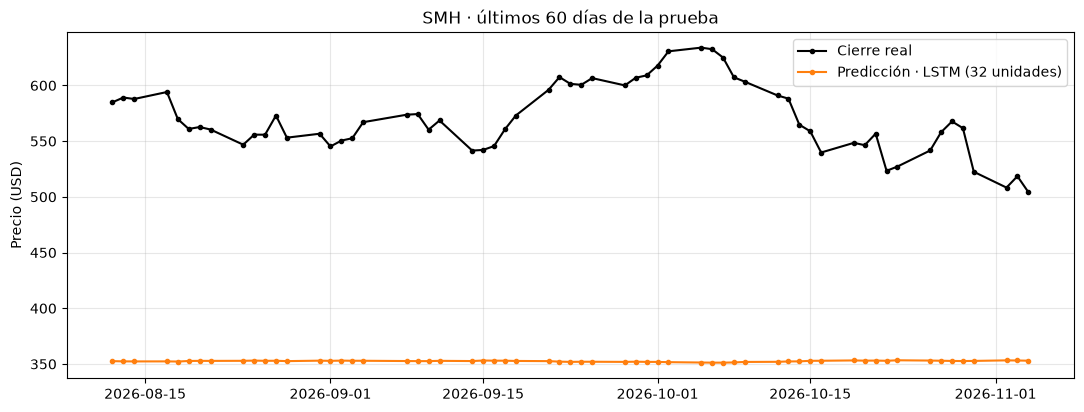

MAE contra el cierre REAL que debía predecir: 200.996
MAE contra el ÚLTIMO cierre que ya conocía:   200.309
Correlación entre cambio predicho y cambio real: +0.190
Sesgo medio (predicción − real) en prueba: -200.996 USD (subestima el precio)


In [14]:
def a_arreglos(dataset):
    X = np.concatenate([x.numpy() for x, _ in dataset])
    y = np.concatenate([y.numpy() for _, y in dataset])
    return X, y

X_test, y_test = a_arreglos(test_ds)
desnorm = lambda v: v * std_close + media_close
real = desnorm(y_test)
ultimo = desnorm(X_test[:, -1, 0])
pred = desnorm(keras.ops.convert_to_numpy(modelo_lstm.predict(X_test, verbose=0))[:, 0])
fechas_obj = fechas[num_train + num_val + delay: num_train + num_val + delay + len(real)]

n_ver = 60
plt.figure(figsize=(13, 4.5))
plt.plot(fechas_obj[-n_ver:], real[-n_ver:], "o-", color="black", markersize=3, label="Cierre real")
plt.plot(fechas_obj[-n_ver:], pred[-n_ver:], "o-", color="tab:orange", markersize=3, label=f"Predicción · {NOMBRE_MODELO}")
plt.title(f"{ticker} · últimos {n_ver} días de la prueba")
plt.ylabel("Precio (USD)")
plt.legend()
plt.show()

mae_vs_real = np.mean(np.abs(pred - real))
mae_vs_ultimo = np.mean(np.abs(pred - ultimo))
corr_cambios = np.corrcoef(pred - ultimo, real - ultimo)[0, 1]
sesgo_medio = np.mean(pred - real)
print(f"MAE contra el cierre REAL que debía predecir: {mae_vs_real:.3f}")
print(f"MAE contra el ÚLTIMO cierre que ya conocía:   {mae_vs_ultimo:.3f}")
print(f"Correlación entre cambio predicho y cambio real: {corr_cambios:+.3f}")
print(f"Sesgo medio (predicción − real) en prueba: {sesgo_medio:+.3f} USD "
      f"({'subestima' if sesgo_medio < 0 else 'sobreestima'} el precio)")

### 5.2 Exactitud direccional (Bloque 8.3)
¿Acierta si mañana sube o baja? Se compara con las líneas base de dirección. Con $n$ días de prueba, un resultado dentro de $50\,\% \pm 1.96\sqrt{0.25/n}$ es compatible con lanzar una moneda.

Días de prueba: 159 · zona de azar: 42.2 % a 57.8 %
Días que subieron · entrenamiento: 51.5 % · prueba: 59.1 %
La LSTM dijo 'sube' en el 0.0 % de los días de prueba



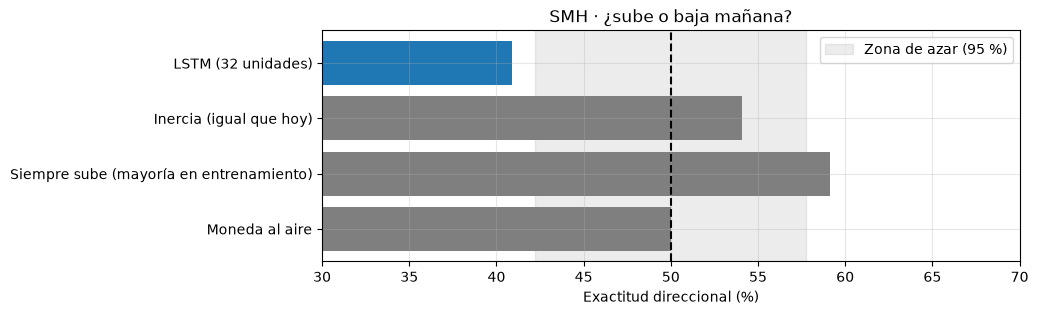

,Exactitud direccional en prueba (%)
Moneda al aire,50.0
Siempre sube (mayoría en entrenamiento),59.1
Inercia (igual que hoy),54.1
LSTM (32 unidades),40.9


In [15]:
X_train, y_train = a_arreglos(crear_dataset(0, num_train - horizonte))
sube_train = y_train > X_train[:, -1, 0]
clase_mayoritaria = bool(sube_train.mean() >= 0.5)
real_sube = real > ultimo
hoy_subio = X_test[:, -1, 0] > X_test[:, -2, 0]

direccion = {
    "Moneda al aire": 50.0,
    f"Siempre {'sube' if clase_mayoritaria else 'baja'} (mayoría en entrenamiento)": np.mean(real_sube == clase_mayoritaria) * 100,
    "Inercia (igual que hoy)": np.mean(real_sube == hoy_subio) * 100,
    NOMBRE_MODELO: np.mean((pred > ultimo) == real_sube) * 100,
}
margen = 1.96 * np.sqrt(0.25 / len(real)) * 100

print(f"Días de prueba: {len(real)} · zona de azar: {50 - margen:.1f} % a {50 + margen:.1f} %")
print(f"Días que subieron · entrenamiento: {sube_train.mean() * 100:.1f} % · prueba: {real_sube.mean() * 100:.1f} %")
print(f"La LSTM dijo 'sube' en el {np.mean(pred > ultimo) * 100:.1f} % de los días de prueba\n")
tabla_dir = pd.Series(direccion, name="Exactitud direccional en prueba (%)").round(1)

plt.figure(figsize=(9, 3))
plt.barh(tabla_dir.index, tabla_dir.values, color=["tab:gray"] * 3 + ["tab:blue"])
plt.axvspan(50 - margen, 50 + margen, color="gray", alpha=0.15, label="Zona de azar (95 %)")
plt.axvline(50, color="black", linestyle="--")
plt.xlim(30, 70)
plt.xlabel("Exactitud direccional (%)")
plt.title(f"{ticker} · ¿sube o baja mañana?")
plt.legend()
plt.show()
tabla_dir.to_frame()

### 5.3 El sesgo del pronóstico recursivo (Bloques 4 y 7)
Con datos reales, el pequeño "jalón" de la red hacia los precios del entrenamiento se corrige cada día; en la recursión **se acumula**. Para medirlo, repetimos el pronóstico recursivo de 30 días desde varios puntos de la **prueba** (cada 5 días) y comparamos su dirección a 30 días con lo que pasó de verdad. Ojo: los orígenes se traslapan, así que no son casos independientes.

c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1412.)
  outputs, h_n, c_n = torch._VF.lstm(


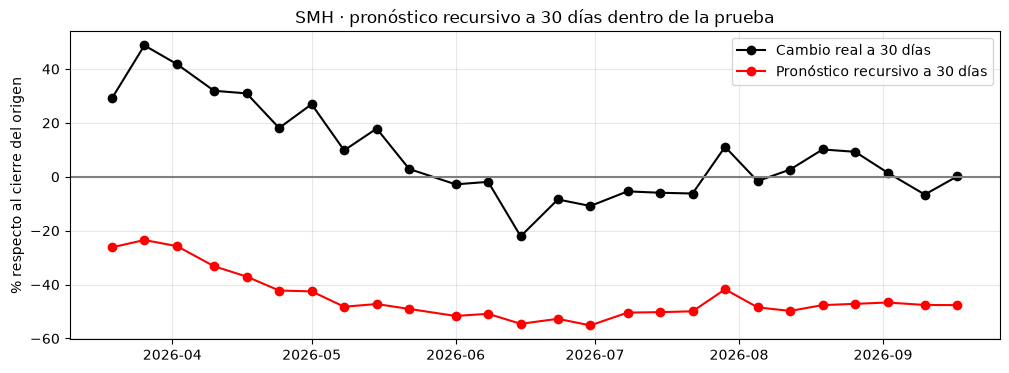

Orígenes evaluados: 26
Acierto de la dirección a 30 días del pronóstico recursivo: 38.5 %  (en esos mismos orígenes el precio subió el 61.5 % de las veces)
Cambio pronosticado promedio: -44.9 % · cambio real promedio: +8.5 %

Último cierre: 504.27 · media del entrenamiento: 166.93 · máximo del entrenamiento: 279.16
Pronóstico a 30 días hábiles: 293.44 (-41.8 %)


,Cambio real 30 d (%),Cambio pronosticado 30 d (%)
Origen,,
2026-07-15,-5.92,-50.230000
2026-07-22,-6.21,-49.930000
2026-07-29,11.12,-41.759998
2026-08-05,-1.60,-48.450001
2026-08-12,2.68,-49.770000
2026-08-19,10.14,-47.619999
2026-08-26,9.27,-47.150002
2026-09-02,1.52,-46.650002
2026-09-10,-6.59,-47.580002


In [16]:
inicio_prueba = num_train + num_val
origenes = range(inicio_prueba + ventana, len(raw_data) - pasos_futuro + 1, 5)
filas_rec = []
for t0 in origenes:
    fut = pronostico_recursivo(modelo_lstm, data_norm[:t0], pasos_futuro)
    base = raw_data[t0 - 1, 0]
    filas_rec.append({"Origen": fechas[t0 - 1].date(),
                      "Cambio real 30 d (%)": (raw_data[t0 + pasos_futuro - 1, 0] / base - 1) * 100,
                      "Cambio pronosticado 30 d (%)": (fut[-1] / base - 1) * 100})
backtest = pd.DataFrame(filas_rec).set_index("Origen")
acierto_30 = np.mean(np.sign(backtest["Cambio real 30 d (%)"]) == np.sign(backtest["Cambio pronosticado 30 d (%)"])) * 100
subio_30 = np.mean(backtest["Cambio real 30 d (%)"] > 0) * 100

plt.figure(figsize=(12, 4))
plt.plot(backtest.index, backtest["Cambio real 30 d (%)"], "o-", color="black", label="Cambio real a 30 días")
plt.plot(backtest.index, backtest["Cambio pronosticado 30 d (%)"], "o-", color="red", label="Pronóstico recursivo a 30 días")
plt.axhline(0, color="gray")
plt.ylabel("% respecto al cierre del origen")
plt.title(f"{ticker} · pronóstico recursivo a 30 días dentro de la prueba")
plt.legend()
plt.show()

ultimo_cierre = raw_data[-1, 0]
print(f"Orígenes evaluados: {len(backtest)}")
print(f"Acierto de la dirección a 30 días del pronóstico recursivo: {acierto_30:.1f} %  "
      f"(en esos mismos orígenes el precio subió el {subio_30:.1f} % de las veces)")
print(f"Cambio pronosticado promedio: {backtest['Cambio pronosticado 30 d (%)'].mean():+.1f} % · "
      f"cambio real promedio: {backtest['Cambio real 30 d (%)'].mean():+.1f} %")
print(f"\nÚltimo cierre: {ultimo_cierre:.2f} · media del entrenamiento: {media_close:.2f} · "
      f"máximo del entrenamiento: {max_train * std_close + media_close:.2f}")
print(f"Pronóstico a 30 días hábiles: {futuro[-1]:.2f} ({(futuro[-1] / ultimo_cierre - 1) * 100:+.1f} %)")
backtest.round(2).tail(10)

### 5.4 Resumen numérico
Todos los números que sostienen la conclusión, en un solo lugar.

In [17]:
print(f"Ticker: {ticker} · usar_volumen: {usar_volumen} · datos hasta {fechas[-1]:%Y-%m-%d}")
print(f"Prueba fuera del rango de entrenamiento: {fuera_de_rango['Prueba']:.1f} %")
print(f"MAE prueba · base: {mae_base_test:.3f} · LSTM: {mae_test:.3f} ({(mae_test / mae_base_test - 1) * 100:+.1f} %)")
print(f"RMSE prueba · base: {rmse_base_test:.3f} · LSTM: {rmse_test:.3f}")
print(f"Retraso de un día · MAE vs. real {mae_vs_real:.3f} · vs. último {mae_vs_ultimo:.3f} · corr. de cambios {corr_cambios:+.3f}")
print(f"Sesgo medio en prueba: {sesgo_medio:+.3f} USD")
print(f"Exactitud direccional (1 día) · LSTM: {direccion[NOMBRE_MODELO]:.1f} % · zona de azar ±{margen:.1f} pts")
print(f"Dirección a 30 días (recursivo, en prueba): {acierto_30:.1f} % · subió el {subio_30:.1f} %")
print(f"Pronóstico 30 días hábiles: {ultimo_cierre:.2f} → {futuro[-1]:.2f} ({(futuro[-1] / ultimo_cierre - 1) * 100:+.1f} %)")

Ticker: SMH · usar_volumen: False · datos hasta 2026-11-04
Prueba fuera del rango de entrenamiento: 100.0 %
MAE prueba · base: 12.393 · LSTM: 200.996 (+1521.8 %)
RMSE prueba · base: 16.094 · LSTM: 210.737
Retraso de un día · MAE vs. real 200.996 · vs. último 200.309 · corr. de cambios +0.190
Sesgo medio en prueba: -200.996 USD
Exactitud direccional (1 día) · LSTM: 40.9 % · zona de azar ±7.8 pts
Dirección a 30 días (recursivo, en prueba): 38.5 % · subió el 61.5 %
Pronóstico 30 días hábiles: 504.27 → 293.44 (-41.8 %)


### 5.5 Respuesta: ¿SMH subirá o bajará en los próximos 30 días?
Mi LSTM dice que SMH va a **bajar** casi 42 % en los próximos 30 días (de 504 a 293 USD), pero la verdad no le creo nada a ese pronóstico.

El problema es que SMH subió muchísimo después del periodo de entrenamiento: el 100 % de los precios de prueba quedó fuera del rango que vio la red, y como las redes no extrapolan, se quedó "atorada" en precios viejos. Por eso su MAE fue de 201 USD contra 12.4 de la línea base, y el sesgo medio salió en −201: siempre predijo por debajo del precio real. Aquí ni siquiera aparece el retraso de un día que vimos en la práctica, porque la red no alcanza a copiar el último cierre. En dirección también falla: dice «baja» casi siempre y por eso acierta solo el 40.9 % a un día y el 38.5 % a 30 días, cuando la acción subió la mayoría de las veces. La caída del −42 % es el sesgo del pronóstico recursivo jalando el precio hacia lo que vio al entrenar, no algo que el modelo sepa del futuro.

Entonces, mi conclusión es que **no puedo decir si va a subir o bajar**. Lo más razonable es suponer que se queda más o menos igual (~504 USD), con un error típico de unos ±68 USD a 30 días (12.4 × √30). Mi confianza en el pronóstico de la red es prácticamente nula. Si lo volviera a hacer, intentaría predecir el rendimiento en vez del precio (Bloque 8.4).

**Recordatorio ético:** es un ejercicio académico, no una recomendación de inversión.